# 第三章 · 简单线性回归：系数估计与置信区间

作者：林泓浩。配套《零基础统计学习指南》。本 Notebook 截止斜率置信区间，不含假设检验。

从上到下运行全部代码块；数据为虚构教学数据，无须联网下载。请在本文件所在的第三章目录运行，图片写入其“图片”文件夹。需要 NumPy、Matplotlib、SciPy 和 IPython。理论假设与完整推导见讲义。

## 代码 3.1.1-01 · 创建三个市场的教学数据

In [1]:
import numpy as np

x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 3.0, 5.0])
print("x:", x)
print("y:", y)
print("shapes:", x.shape, y.shape)


x: [1. 2. 3.]
y: [2. 3. 5.]
shapes: (3,) (3,)


**逐步读代码**

- `import numpy as np` 导入 NumPy，用简短名称 `np` 调用。`np.array` 把列表转换为可逐元素计算的数组；小数写法使本例使用浮点数。

- `x` 是三个市场的广告预算，单位为千元；`y` 是对应销量，单位为千件。同一位置的两个数构成一个样本。这里是虚构教学数据，不是教材 Advertising 数据集。

- 两个数组的 `shape` 都是 `(3,)`，表示有三个元素的一维数组。这里手算单特征公式，用一维数组即可；不要与某些模型接口要求的二维特征矩阵混淆。`print` 显示括号中的内容。

## 代码 3.1.1-02 · 计算均值并中心化

In [2]:
x_mean = x.mean()
y_mean = y.mean()
x_centered = x - x_mean
y_centered = y - y_mean
print("means:", x_mean, y_mean)
print("x_centered:", x_centered)
print("y_centered:", y_centered)
print("centered sums:", x_centered.sum(), y_centered.sum())


means: 2.0 3.3333333333333335
x_centered: [-1.  0.  1.]
y_centered: [-1.33333333 -0.33333333  1.66666667]
centered sums: 0.0 -4.440892098500626e-16


**逐步读代码**

- `.mean()` 对数组元素求算术平均，得到一个数。`x_mean` 是 2，`y_mean` 是 10/3 的浮点近似。

- 数组减去一个数时，NumPy 将这个数作用到每个元素，这叫广播。中心化后仍是形状 `(3,)` 的数组，记录每个观测值偏离均值多少。

- `.sum()` 求元素总和。理论上中心化后的和为零；浮点运算可能显示约 10 的负 16 次方量级的小数，它是数值舍入误差，不是公式失效。

## 代码 3.1.1-03 · 把两个求和式翻译为 NumPy

In [3]:
Sxx = np.sum(x_centered ** 2)
Sxy = np.sum(x_centered * y_centered)
print("Sxx:", Sxx)
print("Sxy:", Sxy)


Sxx: 2.0
Sxy: 3.0


**逐步读代码**

- `** 2` 先对每个元素平方，`np.sum` 再把平方值加起来。因此第一行计算的是离差平方和，不是先求和再平方。

- `x_centered * y_centered` 对应位置逐元素相乘，结果仍是 `(3,)`；外层 `np.sum` 将三个乘积相加，得到一个数。两个数组都中心化了，但乘积之和不必为零。

- `Sxx` 与 `Sxy` 是变量名，大小写必须前后一致。本例得到 2 和 3，分别对应数学公式中的输入离差平方和与交叉离差和。

## 代码 3.1.1-04 · 计算最小二乘斜率与截距

In [4]:
beta1_hat = Sxy / Sxx
beta0_hat = y_mean - beta1_hat * x_mean
print("slope:", beta1_hat)
print("intercept:", beta0_hat)


slope: 1.5
intercept: 0.3333333333333335


**逐步读代码**

- 第一行将交叉离差和除以输入离差平方和。前面已经确认 `Sxx = 2 > 0`，所以本例可以使用这个公式；若所有预算相同，就不能直接相除。

- 第二行先计算斜率乘以预算均值，再从销量均值中减去它。变量名中的 `hat` 对应数学记号中的帽子，表示数据算出的估计值。

- 输出的斜率为 1.5，截距为 1/3 的浮点近似。斜率单位是千件/千元，截距单位是千件。

## 代码 3.1.1-05 · 预测训练样本并计算残差

In [5]:
y_fit = beta0_hat + beta1_hat * x
residual = y - y_fit
print("fitted values:", y_fit)
print("residuals:", residual)
print("residual shape:", residual.shape)


fitted values: [1.83333333 3.33333333 4.83333333]
residuals: [ 0.16666667 -0.33333333  0.16666667]
residual shape: (3,)


**逐步读代码**

- `beta1_hat * x` 把斜率分别乘以三个预算，随后广播加上截距，所以 `y_fit` 是三个训练样本的拟合值，形状为 `(3,)`。

- `y - y_fit` 按同一位置相减，使用的约定始终是实际值减预测值。正残差表示低估，负残差表示高估。

- 这里的残差可以计算，因为这三个样本的真实观测销量已经知道；模型误差项涉及未知的真实回归函数，不能直接与残差画等号。

## 代码 3.1.1-06 · 计算残差平方和与训练 MSE

In [6]:
squared_residual = residual ** 2
rss = np.sum(squared_residual)
train_mse = np.mean(squared_residual)
print("squared residuals:", squared_residual)
print("RSS:", rss)
print("training MSE:", train_mse)
print("square of residual sum:", residual.sum() ** 2)


squared residuals: [0.02777778 0.11111111 0.02777778]
RSS: 0.16666666666666652
training MSE: 0.055555555555555504
square of residual sum: 7.888609052210118e-31


**逐步读代码**

- `squared_residual` 保存逐个残差的平方；`np.sum` 给出 RSS，`np.mean` 给出训练 MSE，后者等于前者除以三个样本。

- 最后一行故意先求残差和再平方，用来对比两种运算。它不是 RSS：正负残差会相互抵消。

- 本例 RSS 为 1/6，训练 MSE 为 1/18。最后一行接近零，只能说明残差和接近零，不能说明每个预测都准确。

## 代码 3.1.1-07 · 对一个新预算作预测

In [7]:
x_new = 4.0
y_new_pred = beta0_hat + beta1_hat * x_new
print("new budget:", x_new)
print("predicted sales:", y_new_pred)


new budget: 4.0
predicted sales: 6.333333333333334


**逐步读代码**

- `x_new` 是一个数，表示新预算为 4 千元；代入已拟合的直线，得到一个预测数值，约为 6.3333 千件。

- 使用新变量 `y_new_pred`，保留前面的训练拟合数组 `y_fit`，方便后续继续计算残差和标准误。

- 4 超出了训练预算范围 1 到 3，这属于外推。公式可以输出数值，但外推是否可靠需要额外判断。没有新市场实际销量，就不能计算它的残差。

## 代码 3.1.1-08 · 画出观测点与拟合直线

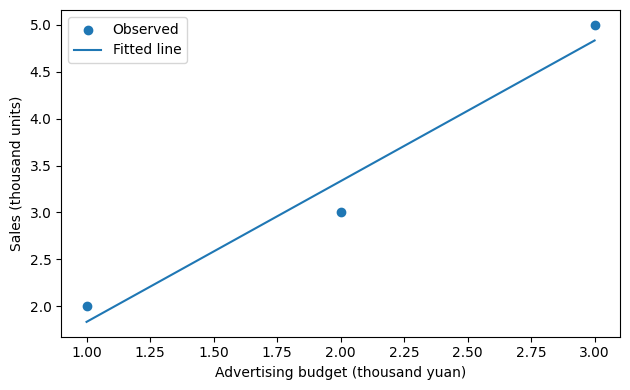

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display

image_dir = Path("图片")
image_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.scatter(x, y, label="Observed")
ax.plot(x, y_fit, label="Fitted line")
ax.set_xlabel("Advertising budget (thousand yuan)")
ax.set_ylabel("Sales (thousand units)")
ax.legend()
fig.tight_layout()
fig.savefig(image_dir / "311-fit.png", dpi=180)
fig.savefig(image_dir / "311-fit.pdf")
display(fig)
plt.close(fig)


**逐步读代码**

- `Path` 管理文件路径；`Path("图片")` 表示工作目录下的图片文件夹。`mkdir(exist_ok=True)` 是路径对象的方法，创建目录，目录已存在时允许继续。请在第三章 Notebook 所在目录运行。

- `plt.subplots` 创建整张画布 `fig` 和绘图区域 `ax`；`figsize` 以英寸指定宽和高。尺寸是可复用的显示设置，不需要背诵。

- `scatter(x, y)` 画实际观测点；`plot(x, y_fit)` 依输入顺序连接拟合值。本例 `x` 已从小到大排列，且拟合值位于同一直线上；实际销量连起来并不等于拟合直线。

- `label` 为图例提供名称；`set_xlabel`、`set_ylabel` 设置坐标轴标题和单位；`legend()` 显示图例。这里使用默认颜色，不需要记忆颜色编码。

- `tight_layout()` 调整边距；路径对象之间的 `/` 拼接文件路径。`savefig` 保存 PNG 和矢量 PDF，`dpi=180` 设置 PNG 分辨率。

- `display(fig)` 在 Notebook 中显示图片，`plt.close(fig)` 关闭后台画布以避免重复显示，已保存的图片和已经显示的输出仍保留。

## 代码 3.1.2-01 · 同一个真实模型可以产生不同的拟合直线

In [9]:
true_mean = 2.0 + 3.0 * x
error_a = np.array([-1.0, 0.0, 1.0])
error_b = np.array([1.0, 0.0, -1.0])

for name, errors in [("A", error_a), ("B", error_b)]:
    y_case = true_mean + errors
    slope_case = np.sum(x_centered * (y_case - y_case.mean())) / Sxx
    intercept_case = y_case.mean() - slope_case * x_mean
    rss_case = np.sum((y_case - (intercept_case + slope_case * x)) ** 2)
    print(name, "sales:", y_case)
    print("slope, intercept, RSS:", slope_case, intercept_case, rss_case)


A sales: [ 4.  8. 12.]
slope, intercept, RSS: 4.0 0.0 0.0
B sales: [ 6.  8. 10.]
slope, intercept, RSS: 2.0 4.0 0.0


**逐步读代码**

- `true_mean` 设置这个新例子的真实平均销量为 2 加 3 倍预算。两组误差是人为指定的示意取值，没有执行随机抽样，也不是声称三点足以验证分布假设。

- 方括号里有两个二元组，分别包含组名和误差数组。`for name, errors in ...` 每次取一组，并把两个内容分别赋给 `name` 与 `errors`；缩进部分每组执行一次。

- `y_case` 是真实均值加上这组误差。随后使用已经推导的相同公式计算本组斜率、截距和 RSS。

- 后缀 `_case` 避免覆盖最初数据的 `beta1_hat`、`beta0_hat`、`y` 和 `residual`，后面的置信区间仍针对最初三个市场。

- 两组 RSS 都为零，斜率却分别为 4 和 2，都不同于真实斜率 3。训练集拟合完美不能保证参数估计准确。

## 代码 3.1.2-02 · 准备噪声方差估计的分子和自由度

In [10]:
n = len(y)
residual_df = n - 2
rss = np.sum(residual ** 2)
print("n:", n)
print("residual degrees of freedom:", residual_df)
print("RSS:", rss)


n: 3
residual degrees of freedom: 1
RSS: 0.16666666666666652


**逐步读代码**

- `len(y)` 返回观测销量的数量，本例为 3。`residual_df = n - 2` 是带截距、单一斜率且输入有变化的模型对应的残差自由度，本例为 1。

- `rss` 重新由最初三个市场的残差计算；不是前一个示意例子的 `rss_case`。

- 使用这个方差估计式之前，需要样本量大于 2、输入离差平方和大于零，以及正文给出的零均值、同方差、不相关误差条件。

## 代码 3.1.2-03 · 计算噪声方差、RSE 和斜率标准误

In [11]:
sigma2_hat = rss / residual_df
rse = np.sqrt(sigma2_hat)
slope_se = rse / np.sqrt(Sxx)
print("estimated noise variance:", sigma2_hat)
print("RSE:", rse)
print("estimated slope SE:", slope_se)


estimated noise variance: 0.16666666666666652
RSE: 0.40824829046386285
estimated slope SE: 0.28867513459481275


**逐步读代码**

- `sigma2_hat` 是 RSS 除以残差自由度，估计真实噪声方差；不要把分母改成 `n`，那样得到的是训练 MSE。

- `np.sqrt` 求平方根；`rse` 是残差标准误，用来估计销量噪声的标准差，单位为千件。方差估计无偏并不意味着开方后的 RSE 也无偏。

- `slope_se` 再除以输入离差平方和的平方根，估计斜率估计量的标准差，单位为千件/千元。它不是下一次销量预测误差，也不是斜率估计误差的绝对上界。

## 代码 3.1.2-04 · 用 t 分布求双侧区间的临界值

In [12]:
from scipy.stats import t

alpha = 0.05
left_probability = 1 - alpha / 2
critical_value = t.ppf(left_probability, df=residual_df)
print("alpha:", alpha)
print("left cumulative probability:", left_probability)
print("critical value:", critical_value)


alpha: 0.05
left cumulative probability: 0.975
critical value: 12.706204736432095


**逐步读代码**

- `from scipy.stats import t` 导入 t 分布工具。这里 `t` 是计算概率分布的对象，不是从样本算出的统计量数值。

- `alpha = 0.05` 表示区间方法未覆盖真参数的总概率为 5%；双侧等尾区间每侧分配一半，因此右端临界值左边累计概率是 `1 - alpha / 2 = 0.975`。

- `ppf` 是分位数函数：给定左侧累计概率，返回对应横坐标。`df` 是自由度参数，使用前面算出的 `residual_df = 1`。

- 输出约 12.7062，大于标准正态的 1.96。这是自由度很小时 t 分布尾部更厚的体现；精确覆盖率依赖正文的正态误差假设。

## 代码 3.1.2-05 · 构造并解释斜率的 95% 置信区间

In [13]:
margin = critical_value * slope_se
ci_lower = beta1_hat - margin
ci_upper = beta1_hat + margin
print("estimated slope:", beta1_hat)
print("margin:", margin)
print("95% interval:", ci_lower, ci_upper)


estimated slope: 1.5
margin: 3.6679653624787822
95% interval: -2.1679653624787822 5.167965362478782


**逐步读代码**

- `margin` 是临界值乘以估计标准误，表示区间的半宽。它不是预测残差，也不是一次估计误差的已知大小。

- `ci_lower` 与 `ci_upper` 分别将半宽从斜率估计值中减去、加上，得到下端点和上端点。

- 区间约为 [-2.168, 5.168]。点估计虽然为正，但这份数据给出的区间很宽；不能仅凭正的点估计就断言斜率稳定地为正。

- 95% 指相同设计与模型条件下，重复抽样、重复构造区间的长期覆盖比例；观测数据给定后，本次区间端点已经固定。

## 代码 3.1.2-06 · 比较不同置信水平的区间宽度

In [14]:
for confidence in [0.90, 0.95, 0.99]:
    alpha_level = 1 - confidence
    critical = t.ppf(1 - alpha_level / 2, df=residual_df)
    half_width = critical * slope_se
    lower = beta1_hat - half_width
    upper = beta1_hat + half_width
    print(f"confidence={confidence:.0%}: [{lower:.3f}, {upper:.3f}]")


confidence=90%: [-0.323, 3.323]
confidence=95%: [-2.168, 5.168]
confidence=99%: [-16.876, 19.876]


**逐步读代码**

- `for` 循环依次取三个置信水平；每一次都用同一份数据、同一个斜率估计和同一个标准误，只改变区间的覆盖目标。

- `alpha_level` 是一减置信水平；依次计算对应分位数、半宽和端点，与上一块代码的步骤一致。

- `f"..."` 是格式化字符串：花括号中写变量，`:.0%` 把小数显示成不带小数位的百分数，`:.3f` 保留三位小数。这只改变显示方式，没有把计算中的数值提前截断。

- 置信水平升高，临界值和区间宽度增大。覆盖目标更高不等于估计更精确；输出格式可以查阅复用，理解区间计算才是核心。